# Multi-task chord refinement: full chord plus quality

A separate from-scratch controlled experiment reuses the original custom encoders, fusion, sinusoidal positions and two manual Transformer blocks. The original full-chord head is retained; a linear quality head reads the same contextual beat representation.

$$L=L_{chord}+0.5L_{quality}.$$

Both losses are unweighted. Inputs and baseline training settings are unchanged. Checkpoint selection uses **full-chord validation CE**, never test performance. Quality re-scoring is disabled. Notebooks 05?08, old checkpoints and the v6 dataset are read-only. New outputs go under `outputs/multitask_transformer/`. Run all cells with the repository `.venv` kernel; CPU/Windows is supported.

## 1. Existing implementation and exact inputs

In [1]:
from pathlib import Path
import sys
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'experiments/rahul/src').is_dir()), None)
if root is None:
    raise RuntimeError('Run this notebook from within the vocal-harmonization repository')
if str(root) not in sys.path:
    sys.path.insert(0,str(root))
import bisect
from dataclasses import asdict
from datetime import datetime, timedelta, timezone
import hashlib
import json
import random
import time
import numpy as np
import torch
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.rahul.src.model import DatasetSpec, ModelConfig, ChordRefinementTransformer, masked_cross_entropy
from experiments.rahul.src.model.checkpoint import save_checkpoint, load_checkpoint
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset, make_dataloader, collate_sequences
print('PyTorch:',torch.__version__,'CUDA available:',torch.cuda.is_available())

Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


PyTorch: 2.14.1+cpu CUDA available: False


In [2]:
import ast,csv,nbformat
from torch.nn import functional as F
from experiments.rahul.src.create_sequences import validate_splits
from experiments.rahul.src.weighted_training import supervised_mask,count_training_targets,metrics_from_confusion,quality_metrics
from experiments.rahul.src.model.multitask_transformer import QualityMapping,MultiTaskChordTransformer,multitask_loss,save_multitask_checkpoint,load_multitask_checkpoint
from experiments.rahul.src.maj7_diagnostics import chord_parts,diagnose_logits
BASELINE_RUN=root/'experiments/rahul/outputs/transformer_training/notebook_full_inputs_20261019_194104_127905'
WEIGHTED_RUN=root/'experiments/rahul/outputs/weighted_transformer/weighted_20261020_003318_832489'
PROTECTED_NOTEBOOKS=[root/'experiments/rahul/notebooks'/name for name in ('05_transformer_architecture.ipynb','06_train_transformer.ipynb','07_train_transformer_weighted.ipynb','08_maj7_failure_analysis.ipynb')]
for p in PROTECTED_NOTEBOOKS:
    old=nbformat.read(p,as_version=4); print(p.name,'code cells:',sum(x.cell_type=='code' for x in old.cells))
baseline_config=json.loads((BASELINE_RUN/'training_config.json').read_text())
BASELINE_NOTEBOOK=PROTECTED_NOTEBOOKS[1]; ARCHITECTURE_NOTEBOOK=PROTECTED_NOTEBOOKS[0]

05_transformer_architecture.ipynb code cells: 14
06_train_transformer.ipynb code cells: 17
07_train_transformer_weighted.ipynb code cells: 15
08_maj7_failure_analysis.ipynb code cells: 11


In [3]:
INPUT_KEYS = (
    'basic_chord_ids', 'melody_pitch_ids', 'melody_timing', 'melody_note_mask',
    'melody_silent', 'key_ids', 'mode_ids', 'roman_ids', 'harmonic_function_ids',
    'genre_features', 'beat_index', 'bar_number', 'beat_position', 'event_duration',
    'relative_bar_number', 'beat_timing_known_mask', 'beat_attention_mask',
)
TARGET_KEYS = ('target_chord_ids','target_loss_mask')
assert len(INPUT_KEYS)==17
print('Inputs:'); print('\n'.join('inputs__'+k for k in INPUT_KEYS))
print('Targets:'); print('\n'.join('targets__'+k for k in TARGET_KEYS))

Inputs:
inputs__basic_chord_ids
inputs__melody_pitch_ids
inputs__melody_timing
inputs__melody_note_mask
inputs__melody_silent
inputs__key_ids
inputs__mode_ids
inputs__roman_ids
inputs__harmonic_function_ids
inputs__genre_features
inputs__beat_index
inputs__bar_number
inputs__beat_position
inputs__event_duration
inputs__relative_bar_number
inputs__beat_timing_known_mask
inputs__beat_attention_mask
Targets:
targets__target_chord_ids
targets__target_loss_mask


## 2. Baseline settings, from-scratch seed and separate run

In [4]:
BASELINE_RUN = root/'experiments/rahul/outputs/transformer_training/notebook_full_inputs_20261019_194104_127905'
BASELINE_NOTEBOOK = root/'experiments/rahul/notebooks/06_train_transformer.ipynb'
ARCHITECTURE_NOTEBOOK = root/'experiments/rahul/notebooks/05_transformer_architecture.ipynb'
baseline_config=json.loads((BASELINE_RUN/'training_config.json').read_text())
baseline_nb=nbformat.read(BASELINE_NOTEBOOK,as_version=4)
setting_names={'SEED':'seed','MAX_EPOCHS':'max_epochs','BATCH_SIZE':'batch_size',
               'LEARNING_RATE':'learning_rate','PATIENCE':'patience','THREADS':'threads'}
notebook_literals={}
for cell in baseline_nb.cells:
    if cell.cell_type!='code': continue
    for statement in ast.parse(cell.source).body:
        if isinstance(statement,ast.Assign):
            for target in statement.targets:
                if isinstance(target,ast.Name) and target.id in setting_names:
                    notebook_literals[target.id]=ast.literal_eval(statement.value)
for name,key in setting_names.items():
    assert notebook_literals[name]==baseline_config[key],f'Baseline settings differ: {name}'
SEED=baseline_config['seed']; MAX_EPOCHS=baseline_config['max_epochs']
BATCH_SIZE=baseline_config['batch_size']; LEARNING_RATE=baseline_config['learning_rate']
PATIENCE=baseline_config['patience']; THREADS=baseline_config['threads']
DEVICE=torch.device(baseline_config['device'])
DATASET_DIR=Path(baseline_config['dataset'])
if not DATASET_DIR.is_dir(): DATASET_DIR=root/'experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
assert ['inputs__'+k for k in INPUT_KEYS]==baseline_config['input_columns']
assert ['targets__'+k for k in TARGET_KEYS]==baseline_config['target_columns']
assert baseline_config['optimizer']=='AdamW'
assert baseline_config['scheduler']=='ReduceLROnPlateau(factor=0.5,patience=1)'
LAMBDA_QUALITY=0.5
ENABLE_QUALITY_RESCORING=False
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(THREADS)
if DEVICE.type=='cuda':
    if not torch.cuda.is_available(): raise RuntimeError('Baseline CUDA device unavailable')
    torch.cuda.manual_seed_all(SEED)
run_stamp=datetime.now(timezone(timedelta(hours=5,minutes=30))).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR=root/'experiments/rahul/outputs/multitask_transformer'/('multitask_'+run_stamp)
print('Output:',RUN_DIR)
display({k:baseline_config[k] for k in ('seed','max_epochs','batch_size','learning_rate','patience','device','threads')})

Output: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\multitask_transformer\multitask_20261020_164527_051309


{'seed': 42,
 'max_epochs': 10,
 'batch_size': 32,
 'learning_rate': 0.001,
 'patience': 3,
 'device': 'cpu',
 'threads': 4}

## 3. Original loaders and split checks

The selected-shard cache and collator are reused from notebook 06. Saved identity-group splits are validated. Inputs use exactly the baseline 17-field whitelist. Auxiliary targets are derived only in the loss; they never enter the encoders. No data, vocabulary or split is regenerated.

In [5]:
def select_batch(batch, device):
    return ({key:batch['inputs'][key].to(device) for key in INPUT_KEYS},
            {key:batch['targets'][key].to(device) for key in TARGET_KEYS})

class CachedSelectedDataset(Dataset):
    def __init__(self, index_path):
        original = SavedSequenceDataset(index_path)
        if original._shards is None:
            self.shards, self.ends = [original], [len(original)]
        else:
            self.shards = [SavedSequenceDataset(p) for p in original._shards]
            self.ends = list(original._ends)
        keep = {'inputs__'+k for k in INPUT_KEYS} | {'targets__'+k for k in TARGET_KEYS}
        for shard in self.shards:
            shard.arrays = {k:v for k,v in shard.arrays.items()
                            if not k.startswith(('inputs__','targets__')) or k in keep}
    def __len__(self):
        return self.ends[-1]
    def __getitem__(self,index):
        if index<0: index+=len(self)
        if not 0<=index<len(self): raise IndexError(index)
        shard = bisect.bisect_right(self.ends,index)
        local = index-(self.ends[shard-1] if shard else 0)
        item = self.shards[shard][local]
        item['metadata']['sequence_index']=index
        return item

def atomic_json(path, value):
    path=Path(path)
    temporary=path.with_suffix(path.suffix+'.tmp')
    temporary.write_text(json.dumps(value,indent=2,allow_nan=False)+'\n',encoding='utf-8')
    temporary.replace(path)

def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()

In [6]:
def write_csv(path, rows):
    if not rows: raise ValueError('Cannot export an empty report')
    fields=list(rows[0])
    with Path(path).open('w',newline='',encoding='utf-8') as stream:
        writer=csv.DictWriter(stream,fieldnames=fields)
        writer.writeheader(); writer.writerows(rows)
    with Path(path).open(newline='',encoding='utf-8') as stream:
        reread=list(csv.DictReader(stream))
    assert len(reread)==len(rows) and list(reread[0])==fields
    for original,saved in zip(rows,reread):
        for key,value in original.items():
            if value is None: assert saved[key]==''
            elif isinstance(value,(float,int)) and not isinstance(value,bool):
                assert float(saved[key])==float(value)
            else: assert saved[key]==str(value)

indices={split:json.loads((DATASET_DIR/f'{split}_sequences.json').read_text()) for split in ('train','validation','test')}
manifest=json.loads((DATASET_DIR/'split_manifest.json').read_text())
all_tracks=[t for group in manifest['splits'].values() for t in group]
validate_splits(manifest,all_tracks)
for split,index in indices.items():
    shard_tracks={str(int(Path(s['path']).stem.removeprefix('track_'))) for s in index['shards']}
    assert shard_tracks==set(manifest['splits'][split])
train_data=CachedSelectedDataset(DATASET_DIR/'train_sequences.json')
validation_data=CachedSelectedDataset(DATASET_DIR/'validation_sequences.json')
train_loader=make_dataloader(train_data,batch_size=BATCH_SIZE,shuffle=True,seed=SEED)
frequency_loader=make_dataloader(train_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
validation_loader=make_dataloader(validation_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
spec=DatasetSpec.from_folder(DATASET_DIR)
reserved_ids=tuple(i for i,label in enumerate(spec.target_labels) if label in ('PAD','UNK'))
protected_paths=[*PROTECTED_NOTEBOOKS,WEIGHTED_RUN/'best_weighted.pt',BASELINE_RUN/'best.pt',
                 BASELINE_RUN/'training_config.json',DATASET_DIR/'feature_vocabularies.json',
                 DATASET_DIR/'target_vocabulary.json',DATASET_DIR/'split_manifest.json']
protected_paths += [DATASET_DIR/f'{split}_sequences.json' for split in indices]
protected_paths += sorted((root/'experiments/rahul/src/model').glob('*.py'))
protected_paths += [root/'experiments/rahul/src/transformer_dataset.py',root/'experiments/rahul/src/encode_features.py']
protected_hashes={str(path):sha256_file(path) for path in protected_paths}
RUN_DIR.mkdir(parents=True,exist_ok=False)
atomic_json(RUN_DIR/'status.json',{'status':'loading_data'})
display({split:{'sequences':idx['sequences'],'real_beats':idx['real_beats']} for split,idx in indices.items()})

{'train': {'sequences': 12718, 'real_beats': 186572},
 'validation': {'sequences': 814, 'real_beats': 11319},
 'test': {'sequences': 990, 'real_beats': 14278}}

## 4. Deterministic quality mapping

Qualities come from parsed saved target labels; Q is not hardcoded. C:maj7/3 maps to maj7 and A:min7/b7 maps to min7. The complete chord target is preserved. N is supervised in both heads. PAD/UNK and unsupported labels map to -100 for the quality loss; a valid full-chord target lacking an auxiliary mapping is excluded only from auxiliary loss. Training counts are descriptive: no class weights are applied.

In [7]:
quality_mapping=QualityMapping.from_chords(spec.target_labels)
Q=len(quality_mapping.labels)
quality_lookup=torch.tensor(quality_mapping.chord_to_quality,dtype=torch.int64)
training_counts=count_training_targets(frequency_loader,spec.num_target_classes,reserved_ids)
mapping_rows=[{'full_chord_id':i,'full_chord_label':label,'quality_id':quality_mapping.chord_to_quality[i],
    'quality_label':quality_mapping.labels[quality_mapping.chord_to_quality[i]] if quality_mapping.chord_to_quality[i]>=0 else None,
    'valid_training_targets':int(training_counts[i])} for i,label in enumerate(spec.target_labels)]
atomic_json(RUN_DIR/'chord_quality_mapping.json',{'quality_labels':quality_mapping.labels,'chord_to_quality':quality_mapping.chord_to_quality,
    'full_chord_labels':spec.target_labels,'policy':'N supervised; PAD/UNK and unsupported quality maps -100; inversion does not change quality.'})
write_csv(RUN_DIR/'chord_quality_mapping.csv',mapping_rows)
quality_train_counts=torch.zeros(Q,dtype=torch.int64)
for i,count in enumerate(training_counts):
    if quality_lookup[i]>=0: quality_train_counts[quality_lookup[i]]+=count
print('Full-chord coordinates:',spec.num_target_classes,'Quality categories:',Q)
display([{'quality_id':i,'quality':q,'train_targets':int(quality_train_counts[i])} for i,q in enumerate(quality_mapping.labels)])
from html import escape
from IPython.display import HTML
def render_table(rows,percentage_keys=()):
    if not rows:return HTML('<p>No supported examples.</p>')
    headers=list(rows[0]); body=[]
    for row in rows:
        values=['N/A' if row[k] is None else (f'{100*row[k]:.2f}%' if k in percentage_keys else str(row[k])) for k in headers]
        body.append('<tr>'+''.join('<td style="padding:5px 9px">'+escape(v)+'</td>' for v in values)+'</tr>')
    return HTML('<div style="max-height:500px;overflow:auto"><table><tr>'+''.join('<th style="padding:7px">'+escape(k)+'</th>' for k in headers)+'</tr>'+''.join(body)+'</table></div>')
display(render_table(mapping_rows))

Full-chord coordinates: 402 Quality categories: 13


[{'quality_id': 0, 'quality': '7', 'train_targets': 7409},
 {'quality_id': 1, 'quality': '9', 'train_targets': 101},
 {'quality_id': 2, 'quality': 'N', 'train_targets': 14904},
 {'quality_id': 3, 'quality': 'aug', 'train_targets': 39},
 {'quality_id': 4, 'quality': 'dim', 'train_targets': 259},
 {'quality_id': 5, 'quality': 'dim7', 'train_targets': 2},
 {'quality_id': 6, 'quality': 'hdim7', 'train_targets': 230},
 {'quality_id': 7, 'quality': 'maj', 'train_targets': 79843},
 {'quality_id': 8, 'quality': 'maj7', 'train_targets': 3284},
 {'quality_id': 9, 'quality': 'min', 'train_targets': 61655},
 {'quality_id': 10, 'quality': 'min7', 'train_targets': 16223},
 {'quality_id': 11, 'quality': 'min9', 'train_targets': 741},
 {'quality_id': 12, 'quality': 'sus4', 'train_targets': 177}]

full_chord_id,full_chord_label,quality_id,quality_label,valid_training_targets
0,PAD,-100,N/A,0
1,UNK,-100,N/A,0
2,N,2,N,14904
3,A#:7,0,7,362
4,A#:7/2,0,7,18
5,A#:7/3,0,7,20
6,A#:7/5,0,7,2
7,A#:7/6,0,7,17
8,A#:7/b2,0,7,16
9,A#:aug,3,aug,4


## 5. Fresh initialization and real-data smoke test

Shared parameters are compared with a fresh baseline initialized with the same seed. No trained checkpoint initializes this model. The auxiliary head uses normal Linear initialization in a forked RNG, preserving the baseline dropout RNG state. This eval-mode forward/backward check updates no parameters, checks both gradients and variable-length padding, then clears gradients.

In [8]:
model_config=ModelConfig(**baseline_config['model'])
model=MultiTaskChordTransformer(spec,model_config,quality_mapping).to(DEVICE)
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(SEED)
    fresh_baseline=ChordRefinementTransformer(spec,model_config).to(DEVICE)
for name,value in fresh_baseline.state_dict().items(): torch.testing.assert_close(value,model.state_dict()[name],rtol=0,atol=0)
del fresh_baseline
from experiments.rahul.src.inspect_transformer import mixed_length_examples
example_batch=collate_sequences(mixed_length_examples(DATASET_DIR))
example_inputs,example_targets=select_batch(example_batch,DEVICE)
model.eval(); before={name:p.detach().clone() for name,p in model.named_parameters()}
smoke=model(example_inputs,return_details=True)
losses=multitask_loss(smoke,example_targets,example_inputs['beat_attention_mask'],model.chord_to_quality,LAMBDA_QUALITY,reserved_ids)
losses['total_loss'].backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
assert model.classifier.weight.grad.norm()>0 and model.quality_classifier.weight.grad.norm()>0
assert all(torch.equal(before[name],p) for name,p in model.named_parameters())
padding=~example_inputs['beat_attention_mask']
assert (smoke['chord_logits'][padding]==0).all() and (smoke['quality_logits'][padding]==0).all()
assert torch.isfinite(smoke['chord_logits']).all() and torch.isfinite(smoke['quality_logits']).all()
smoke_report={'real_lengths':example_inputs['beat_attention_mask'].sum(-1).tolist(),'encoded_shape':list(smoke['details']['encoded'].shape),
    'chord_shape':list(smoke['chord_logits'].shape),'quality_shape':list(smoke['quality_logits'].shape),
    'chord_loss':float(losses['chord_loss'].detach()),'quality_loss':float(losses['quality_loss'].detach()),
    'combined_loss':float(losses['total_loss'].detach()),'both_heads_receive_gradients':True,
    'shared_initialization_matches_fresh_baseline':True,'no_optimizer_step':True,'parameters':sum(p.numel() for p in model.parameters())}
model.zero_grad(set_to_none=True); atomic_json(RUN_DIR/'smoke_test.json',smoke_report); display(smoke_report)

{'real_lengths': [12, 16, 20],
 'encoded_shape': [3, 20, 128],
 'chord_shape': [3, 20, 402],
 'quality_shape': [3, 20, 13],
 'chord_loss': 6.036783695220947,
 'quality_loss': 3.18851375579834,
 'combined_loss': 7.631040573120117,
 'both_heads_receive_gradients': True,
 'shared_initialization_matches_fresh_baseline': True,
 'no_optimizer_step': True,
 'parameters': 350751}

## 6. Separate masked task losses and validation quality scores

Full chord uses valid real supervision; quality additionally requires a valid mapping. Empty masks give differentiable zero. Epoch losses use separate task denominators. Quality accuracy/macro F1 are auxiliary-head metrics, not exact full-chord scores. Macro F1 includes qualities with positive reference support in this evaluated split, including N.

In [9]:
def run_multitask_epoch(model,loader,device,optimizer=None,label='',log_every=100):
    training=optimizer is not None; model.train(training)
    chord_sum=quality_sum=0.; chord_count=quality_count=chord_correct=quality_correct=beats=sequences=steps=0
    qconf=torch.zeros(Q,Q,dtype=torch.int64); started=time.perf_counter()
    for number,batch in enumerate(loader,1):
        inputs,targets=select_batch(batch,device)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            output=model(inputs)
            loss=multitask_loss(output,targets,inputs['beat_attention_mask'],model.chord_to_quality,LAMBDA_QUALITY,reserved_ids)
            if not all(torch.isfinite(loss[k]) for k in ('chord_loss','quality_loss','total_loss')): raise FloatingPointError('Non-finite task loss')
            if not torch.isfinite(output['chord_logits']).all() or not torch.isfinite(output['quality_logits']).all(): raise FloatingPointError('Non-finite logits')
            if training and loss['chord_mask'].any():
                loss['total_loss'].backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),baseline_config['clip_norm'],error_if_nonfinite=True)
                optimizer.step(); steps+=1
        cm,qm=loss['chord_mask'],loss['quality_mask']; nc,nq=int(cm.sum()),int(qm.sum())
        chord_sum+=float(loss['chord_loss'].detach())*nc; quality_sum+=float(loss['quality_loss'].detach())*nq
        chord_count+=nc; quality_count+=nq
        with torch.no_grad():
            chord_correct+=int((output['chord_logits'].argmax(-1)[cm]==targets['target_chord_ids'][cm]).sum())
            truth=loss['quality_targets'][qm]; predicted=output['quality_logits'].argmax(-1)[qm]
            quality_correct+=int((truth==predicted).sum())
            qconf+=torch.bincount((truth*Q+predicted).cpu(),minlength=Q*Q).reshape(Q,Q)
        beats+=int(inputs['beat_attention_mask'].sum()); sequences+=len(inputs['beat_attention_mask'])
        if log_every and (number==1 or number%log_every==0): print(f'{label} batch {number}/{len(loader)} chord CE={chord_sum/max(chord_count,1):.5f} quality CE={quality_sum/max(quality_count,1):.5f}',flush=True)
    if not chord_count: raise ValueError('No valid full-chord targets')
    qm,_=metrics_from_confusion(qconf,quality_mapping.labels,reserved_ids=())
    chord_loss=chord_sum/chord_count; quality_loss=quality_sum/quality_count if quality_count else 0.
    return {'chord_loss':chord_loss,'quality_loss':quality_loss,'combined_loss':chord_loss+LAMBDA_QUALITY*quality_loss,
        'accuracy':chord_correct/chord_count,'quality_accuracy':quality_correct/quality_count if quality_count else None,
        'quality_macro_f1':qm['macro_f1'],'valid_targets':chord_count,'quality_targets':quality_count,
        'real_beats':beats,'sequences':sequences,'optimizer_steps':steps,'seconds':time.perf_counter()-started}
optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=baseline_config['weight_decay'])
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,factor=.5,patience=1)
experiment_config={**baseline_config,'run_dir':str(RUN_DIR),'lambda_quality':LAMBDA_QUALITY,'quality_labels':quality_mapping.labels,'quality_count':Q,
    'loss':'unweighted full-chord CE + lambda * unweighted quality CE','selection':'minimum full-chord validation CE',
    'initialization':'from scratch; shared initialization matches fresh baseline; extra head forked RNG',
    'quality_rescoring_enabled':False,'protected_hashes':protected_hashes,'multitask_parameters':sum(p.numel() for p in model.parameters())}
atomic_json(RUN_DIR/'experiment_config.json',experiment_config)
initial_validation=run_multitask_epoch(model,validation_loader,DEVICE,label='Initial validation',log_every=0)
atomic_json(RUN_DIR/'initial_validation.json',initial_validation); display(initial_validation)

{'chord_loss': 6.053405601880077,
 'quality_loss': 3.1160501948605464,
 'combined_loss': 7.61143069931035,
 'accuracy': 0.01141430354913501,
 'quality_accuracy': 0.011592652042090245,
 'quality_macro_f1': 0.015082354236125466,
 'valid_targets': 11214,
 'quality_targets': 11214,
 'real_beats': 11319,
 'sequences': 814,
 'optimizer_steps': 0,
 'seconds': 1.7280635999923106}

## 7. Train from scratch; select only by full-chord validation CE

In [10]:
if (RUN_DIR/'history.json').exists():
    raise RuntimeError('This run has training history. Run All to create a fresh run directory.')
history = []
best_loss, best_epoch, stale = float('inf'), 0, 0
training_started = time.perf_counter()
try:
    for epoch in range(1,MAX_EPOCHS+1):
        atomic_json(RUN_DIR/'status.json',{'status':'training','epoch':epoch,'max_epochs':MAX_EPOCHS})
        current_lr = optimizer.param_groups[0]['lr']
        train_metrics = run_multitask_epoch(model,train_loader,DEVICE,optimizer,label=f'Epoch {epoch} train')
        validation_metrics = run_multitask_epoch(model,validation_loader,DEVICE,label=f'Epoch {epoch} validation',log_every=0)
        assert train_metrics['sequences']==indices['train']['sequences']
        assert train_metrics['real_beats']==indices['train']['real_beats']
        assert validation_metrics['sequences']==indices['validation']['sequences']
        scheduler.step(validation_metrics['chord_loss'])
        improved = validation_metrics['chord_loss']<best_loss
        if improved:
            best_loss,best_epoch,stale = validation_metrics['chord_loss'],epoch,0
            save_multitask_checkpoint(RUN_DIR/'best_multitask.pt.tmp',model,LAMBDA_QUALITY)
            (RUN_DIR/'best_multitask.pt.tmp').replace(RUN_DIR/'best_multitask.pt')
        else:
            stale += 1
        history.append({'epoch':epoch,'learning_rate':current_lr,'train':train_metrics,
                        'validation':validation_metrics,'saved_best':improved})
        atomic_json(RUN_DIR/'history.json',history)
        write_csv(RUN_DIR/'training_history.csv',[{'epoch':r['epoch'],'learning_rate':r['learning_rate'],
            'train_chord_loss':r['train']['chord_loss'],'train_quality_loss':r['train']['quality_loss'],'train_combined_loss':r['train']['combined_loss'],
            'validation_chord_loss':r['validation']['chord_loss'],'validation_quality_loss':r['validation']['quality_loss'],'validation_combined_loss':r['validation']['combined_loss'],
            'train_chord_accuracy':r['train']['accuracy'],'validation_chord_accuracy':r['validation']['accuracy'],
            'train_quality_accuracy':r['train']['quality_accuracy'],'validation_quality_accuracy':r['validation']['quality_accuracy'],
            'validation_quality_macro_f1':r['validation']['quality_macro_f1'],'saved_best':r['saved_best']} for r in history])
        torch.save({'epoch':epoch,'model_config':asdict(model_config),'spec':asdict(spec),
                    'quality_mapping':asdict(quality_mapping),'lambda_quality':LAMBDA_QUALITY,'model_state_dict':model.state_dict(),'optimizer_state_dict':optimizer.state_dict(),
                    'scheduler_state_dict':scheduler.state_dict(),'best_epoch':best_epoch,
                    'best_validation_loss':best_loss,'rng_state':torch.get_rng_state(),
                    'shuffle_rng_state':train_loader.generator.get_state()},RUN_DIR/'last_multitask_training_state.pt.tmp')
        (RUN_DIR/'last_multitask_training_state.pt.tmp').replace(RUN_DIR/'last_multitask_training_state.pt')
        print(f'Epoch {epoch}: train loss {train_metrics["chord_loss"]:.5f}, '
              f'validation loss {validation_metrics["chord_loss"]:.5f}, '
              f'validation accuracy {validation_metrics["accuracy"]:.2%}; best epoch {best_epoch}',flush=True)
        if stale>=PATIENCE:
            print('Early stopping: validation loss did not improve.',flush=True)
            break
    atomic_json(RUN_DIR/'status.json',{'status':'trained_pending_evaluation',
                                     'completed_epochs':len(history),'best_epoch':best_epoch})
except BaseException as exc:
    atomic_json(RUN_DIR/'status.json',{'status':'interrupted' if isinstance(exc,KeyboardInterrupt) else 'failed',
                                     'error':repr(exc),'completed_epochs':len(history)})
    raise
print('Training seconds:',round(time.perf_counter()-training_started,2))

Epoch 1 train batch 1/398 chord CE=6.30764 quality CE=3.01210


Epoch 1 train batch 100/398 chord CE=1.80934 quality CE=0.66836


Epoch 1 train batch 200/398 chord CE=1.24119 quality CE=0.48220


Epoch 1 train batch 300/398 chord CE=1.02440 quality CE=0.40818


Epoch 1: train loss 0.90596, validation loss 0.57476, validation accuracy 86.70%; best epoch 1


...

Epoch 4 train batch 200/398 chord CE=0.32244 quality CE=0.13395


Epoch 4 train batch 300/398 chord CE=0.31743 quality CE=0.13223


Epoch 4: train loss 0.31261, validation loss 0.60407, validation accuracy 85.56%; best epoch 1


Early stopping: validation loss did not improve.


Training seconds: 282.81


## 8. Full-chord, auxiliary quality and combined loss/accuracy curves

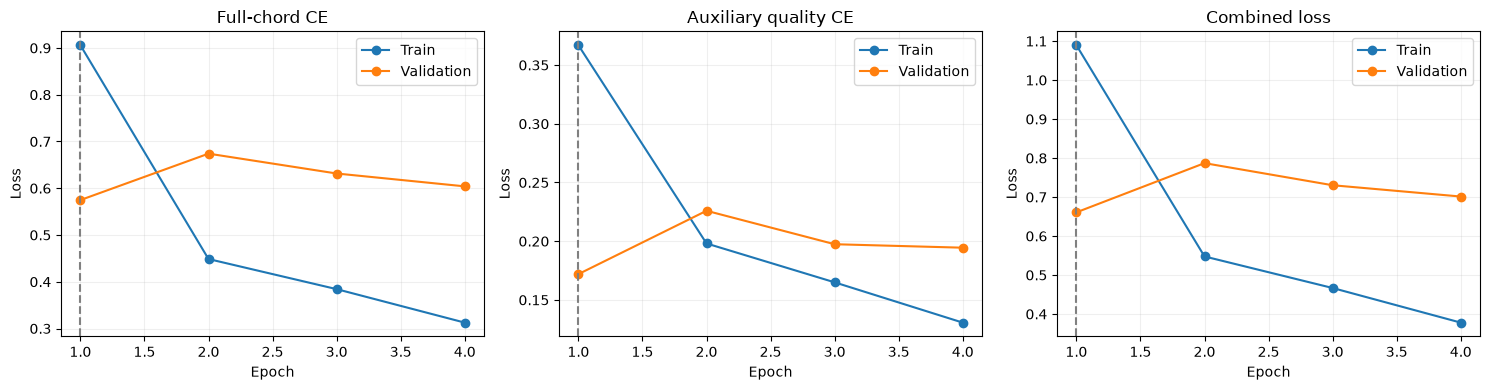

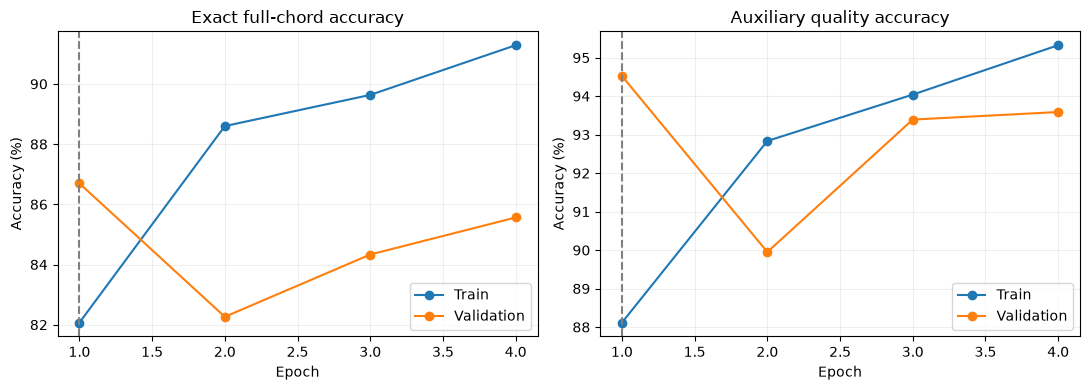

In [11]:
epochs=[r['epoch'] for r in history]
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,key,title in zip(axes,('chord_loss','quality_loss','combined_loss'),('Full-chord CE','Auxiliary quality CE','Combined loss')):
    for split,name in [('train','Train'),('validation','Validation')]: ax.plot(epochs,[r[split][key] for r in history],marker='o',label=name)
    ax.set(xlabel='Epoch',ylabel='Loss',title=title); ax.axvline(best_epoch,ls='--',c='gray'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(RUN_DIR/'task_loss_curves.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,key,title in zip(axes,('accuracy','quality_accuracy'),('Exact full-chord accuracy','Auxiliary quality accuracy')):
    for split,name in [('train','Train'),('validation','Validation')]: ax.plot(epochs,[100*r[split][key] for r in history],marker='o',label=name)
    ax.set(xlabel='Epoch',ylabel='Accuracy (%)',title=title); ax.axvline(best_epoch,ls='--',c='gray'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(RUN_DIR/'task_accuracy_curves.png',dpi=160); plt.show()

## 9. Identical held-out evaluation for all three full-chord heads

Full-chord predictions use raw chord-head logits only. No quality gating, re-ranking or reference-dependent inference is used. Top-k includes all saved output coordinates; reserved predictions remain errors. Macro F1 averages classes with positive reference support in this split; zero-support classes remain in reports. N stays supervised. Auxiliary-head metrics exist only for the multi-task model.

In [12]:
test_data=CachedSelectedDataset(DATASET_DIR/'test_sequences.json')
test_loader=make_dataloader(test_data,batch_size=BATCH_SIZE,shuffle=False,seed=SEED)
feature_state=json.loads((DATASET_DIR/'feature_vocabularies.json').read_text())
basic_labels=feature_state['vocabs']['basic_chord_canonical']['id_to_token']
label_parts=[chord_parts(label) for label in spec.target_labels]
maj7_target_ids=[i for i,(_,quality) in enumerate(label_parts) if quality=='maj7']
maj7_quality_id=quality_mapping.labels.index('maj7')
def evaluate_model(model,loader,is_multitask=False):
    model.eval()
    confusion=torch.zeros(spec.num_target_classes,spec.num_target_classes,dtype=torch.int64)
    auxiliary_confusion=torch.zeros(Q,Q,dtype=torch.int64) if is_multitask else None
    total=top3=top5=musical=correct_root_wrong_quality=0; ce_sum=0.; maj7_rows=[]; examples=[]
    with torch.no_grad():
        for batch in loader:
            inputs,targets=select_batch(batch,DEVICE)
            mask=supervised_mask(targets,inputs['beat_attention_mask'],spec.num_target_classes,reserved_ids)
            output=model(inputs); logits=output['chord_logits'] if is_multitask else output
            assert torch.isfinite(logits).all()
            ids=targets['target_chord_ids'][mask]; selected=logits[mask]
            predicted=selected.argmax(-1); ranked=selected.topk(5,-1).indices
            total+=len(ids); top3+=int((ranked[:,:3]==ids.unsqueeze(-1)).any(-1).sum()); top5+=int((ranked==ids.unsqueeze(-1)).any(-1).sum())
            ce_sum+=float(F.cross_entropy(selected,ids,reduction='sum')) if len(ids) else 0.
            confusion+=torch.bincount((ids*spec.num_target_classes+predicted).cpu(),minlength=spec.num_target_classes**2).reshape(spec.num_target_classes,spec.num_target_classes)
            qtargets=quality_lookup.to(DEVICE)[targets['target_chord_ids'].clamp(0,spec.num_target_classes-1)]
            qm=mask & (qtargets>=0)
            if is_multitask:
                qpred=output['quality_logits'].argmax(-1)
                assert torch.isfinite(output['quality_logits']).all()
                auxiliary_confusion+=torch.bincount((qtargets[qm]*Q+qpred[qm]).cpu(),minlength=Q*Q).reshape(Q,Q)
            for (b,t),target_id,predicted_id in zip(mask.nonzero().tolist(),ids.tolist(),predicted.tolist()):
                root_ref,quality_ref=label_parts[target_id]; root_pred,quality_pred=label_parts[predicted_id]
                if root_ref is not None:
                    musical+=1; correct_root_wrong_quality+=int(root_ref==root_pred and quality_ref!=quality_pred)
                if quality_ref=='maj7':
                    detail=diagnose_logits(logits[b,t].cpu(),target_id,list(spec.target_labels))
                    maj7_rows.append({'track_id':batch['metadata'][b]['track_id'],'beat_index':int(inputs['beat_index'][b,t]),
                        'basic_chord':basic_labels[int(inputs['basic_chord_ids'][b,t])],
                        'reference_chord':spec.target_labels[target_id],'predicted_chord':spec.target_labels[predicted_id],
                        'reference_quality':quality_ref,'full_head_predicted_quality':quality_pred,
                        'auxiliary_predicted_quality':quality_mapping.labels[int(qpred[b,t])] if is_multitask else None,
                        'exact_correct':bool(target_id==predicted_id),'top3_correct':detail['top3_correct'],'top5_correct':detail['top5_correct'],
                        'reference_probability':detail['reference_probability'],'predicted_as_ordinary_maj':quality_pred=='maj',
                        'correct_root_wrong_quality':root_ref==root_pred and quality_ref!=quality_pred,'top3':detail['top5'][:3]})
                if is_multitask:
                    values,classes=logits[b,t].softmax(-1).topk(3)
                    examples.append({'track_id':batch['metadata'][b]['track_id'],'beat_index':int(inputs['beat_index'][b,t]),
                        'basic_chord':basic_labels[int(inputs['basic_chord_ids'][b,t])],
                        'reference_chord':spec.target_labels[target_id],'predicted_chord':spec.target_labels[predicted_id],
                        'reference_quality':quality_ref or spec.target_labels[target_id],
                        'predicted_quality':quality_mapping.labels[int(qpred[b,t])],
                        'exact_correct':target_id==predicted_id,'quality_correct':bool(qtargets[b,t]>=0 and qpred[b,t]==qtargets[b,t]),
                        'top3':[{'label':spec.target_labels[int(i)],'probability':float(p)} for p,i in zip(values,classes)]})
    summary,per_class=metrics_from_confusion(confusion,spec.target_labels,reserved_ids)
    summary.update(unweighted_ce=ce_sum/total,top3_accuracy=top3/total,top5_accuracy=top5/total,
        musical_targets=musical,correct_root_wrong_quality=correct_root_wrong_quality,
        correct_root_wrong_quality_fraction=correct_root_wrong_quality/musical if musical else None)
    quality_summary=quality_class_rows=None
    if is_multitask:
        quality_summary,quality_class_rows=metrics_from_confusion(auxiliary_confusion,quality_mapping.labels,reserved_ids=())
        quality_summary['macro_policy']='Auxiliary qualities with positive test-reference support; N included.'
    return {'metrics':summary,'per_class':per_class,'per_quality_exact':quality_metrics(confusion,spec.target_labels),
        'confusion':confusion,'quality_metrics':quality_summary,'quality_per_class':quality_class_rows,
        'quality_confusion':auxiliary_confusion,'maj7_examples':maj7_rows,'examples':examples}
selected_model=load_multitask_checkpoint(RUN_DIR/'best_multitask.pt',DATASET_DIR,DEVICE)
original_model=load_checkpoint(BASELINE_RUN/'best.pt',DATASET_DIR,DEVICE)
weighted_model=load_checkpoint(WEIGHTED_RUN/'best_weighted.pt',DATASET_DIR,DEVICE)
assert asdict(selected_model.config)==asdict(original_model.config)==asdict(weighted_model.config)
evaluations={}
for name,model_to_evaluate,multi in [('original',original_model,False),('weighted',weighted_model,False),('multitask',selected_model,True)]:
    evaluations[name]=evaluate_model(model_to_evaluate,test_loader,multi)
    write_csv(RUN_DIR/f'{name}_per_chord.csv',evaluations[name]['per_class'])
    write_csv(RUN_DIR/f'{name}_per_quality_exact.csv',evaluations[name]['per_quality_exact'])
    atomic_json(RUN_DIR/f'{name}_maj7_examples.json',evaluations[name]['maj7_examples'])
write_csv(RUN_DIR/'auxiliary_quality_evaluation.csv',evaluations['multitask']['quality_per_class'])
atomic_json(RUN_DIR/'full_head_metrics.json',{name:data['metrics'] for name,data in evaluations.items()})
atomic_json(RUN_DIR/'auxiliary_quality_metrics.json',evaluations['multitask']['quality_metrics'])
print('Full-chord heads:'); display({name:data['metrics'] for name,data in evaluations.items()})
print('Auxiliary head, multi-task only:'); display(evaluations['multitask']['quality_metrics'])
display(render_table(evaluations['multitask']['quality_per_class'],('precision','recall','f1')))

Full-chord heads:


{'original': {'valid_targets': 14077,
  'exact_correct': 11192,
  'accuracy': 0.7950557647225971,
  'macro_f1': 0.32597766423563834,
  'weighted_f1': 0.7349953243341616,
  'macro_classes': 104,
  'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
  'unweighted_ce': 0.8552253938850933,
  'top3_accuracy': 0.9417489521915181,
  'top5_accuracy': 0.9848689351424309,
  'musical_targets': 12965,
  'correct_root_wrong_quality': 2484,
  'correct_root_wrong_quality_fraction': 0.19159274971075974},
 'weighted': {'valid_targets': 14077,
  'exact_correct': 11050,
  'accuracy': 0.7849683881508844,
  'macro_f1': 0.3198755370699484,
  'weighted_f1': 0.7366717045868174,
  'macro_classes': 104,
  'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
  'unweighted_ce': 0.9244743233895009,
  'top3_accuracy': 0.9246288271648789,
  'top5_accuracy': 0.9715138168643888,
  'musical_targets': 12965,
  'correct_r

Auxiliary head, multi-task only:


{'valid_targets': 14077,
 'exact_correct': 11729,
 'accuracy': 0.8332030972508347,
 'macro_f1': 0.5114608579800954,
 'weighted_f1': 0.7775115794481967,
 'macro_classes': 8,
 'macro_policy': 'Auxiliary qualities with positive test-reference support; N included.'}

target_id,reference_chord,quality,reserved,support,predicted_count,correct,precision,recall,f1,included_in_macro
0,7,7,False,325,330,325,98.48%,100.00%,99.24%,True
1,9,9,False,0,0,0,N/A,N/A,N/A,False
2,N,N,False,1112,1112,1112,100.00%,100.00%,100.00%,True
3,aug,aug,False,8,0,0,N/A,0.00%,0.00%,True
4,dim,dim,False,7,0,0,N/A,0.00%,0.00%,True
5,dim7,dim7,False,0,0,0,N/A,N/A,N/A,False
6,hdim7,hdim7,False,0,0,0,N/A,N/A,N/A,False
7,maj,maj,False,5040,5960,5031,84.41%,99.82%,91.47%,True
8,maj7,maj7,False,926,16,2,12.50%,0.22%,0.42%,True
9,min,min,False,5019,6287,4953,78.78%,98.68%,87.62%,True


## 10. Major-seventh diagnosis and representative successes/failures

Recount valid maj7 targets in the unchanged splits. Full-label top-k is separate from auxiliary quality precision/recall. Predictions as ordinary maj include any root/inversion and are explicitly counted; correct-root/wrong-quality cases are also reported. Representative failures are included even if no maj7 successes exist.

In [13]:
maj7_split_support={'train':int(training_counts[maj7_target_ids].sum())}
for split,data in [('validation',validation_data),('test',test_data)]:
    counts=count_training_targets(make_dataloader(data,batch_size=BATCH_SIZE,shuffle=False),spec.num_target_classes,reserved_ids)
    maj7_split_support[split]=int(counts[maj7_target_ids].sum())
maj7_diagnostic=[]; wrong_predictions=[]
for name,data in evaluations.items():
    rows=data['maj7_examples']; support=len(rows); counts={}
    for row in rows:
        if not row['exact_correct']: counts[row['predicted_chord']]=counts.get(row['predicted_chord'],0)+1
    maj7_diagnostic.append({'model':name,'maj7_targets':support,'exact_top1_accuracy':sum(r['exact_correct'] for r in rows)/support,
        'exact_top3_accuracy':sum(r['top3_correct'] for r in rows)/support,'exact_top5_accuracy':sum(r['top5_correct'] for r in rows)/support,
        'predicted_as_ordinary_maj_fraction':sum(r['predicted_as_ordinary_maj'] for r in rows)/support,
        'correct_root_wrong_quality_fraction':sum(r['correct_root_wrong_quality'] for r in rows)/support,
        'mean_correct_full_chord_probability':float(np.mean([r['reference_probability'] for r in rows]))})
    for predicted,count in sorted(counts.items(),key=lambda item:(-item[1],item[0])):
        wrong_predictions.append({'model':name,'incorrect_predicted_chord':predicted,'count':count,'fraction_of_maj7':count/support})
write_csv(RUN_DIR/'maj7_diagnostic.csv',maj7_diagnostic); write_csv(RUN_DIR/'maj7_incorrect_predictions.csv',wrong_predictions)
atomic_json(RUN_DIR/'maj7_split_counts.json',maj7_split_support)
aux_maj7=evaluations['multitask']['quality_per_class'][maj7_quality_id]
print('Maj7 split support:'); display(maj7_split_support)
display(render_table(maj7_diagnostic,('exact_top1_accuracy','exact_top3_accuracy','exact_top5_accuracy','predicted_as_ordinary_maj_fraction','correct_root_wrong_quality_fraction','mean_correct_full_chord_probability')))
print('Auxiliary maj7 precision/recall/F1:'); display(aux_maj7)
display(render_table(wrong_predictions[:30],('fraction_of_maj7',)))
all_examples=evaluations['multitask']['examples']; representatives=[]; seen=set()
for reason,candidates in [('maj7_success',[r for r in all_examples if r['reference_quality']=='maj7' and r['exact_correct']]),
    ('maj7_failure',[r for r in all_examples if r['reference_quality']=='maj7' and not r['exact_correct']]),
    ('quality_correct_full_chord_wrong',[r for r in all_examples if r['quality_correct'] and not r['exact_correct']]),
    ('other_quality_failure',[r for r in all_examples if r['reference_quality']!='maj7' and not r['exact_correct']]),
    ('other_quality_success',[r for r in all_examples if r['reference_quality']!='maj7' and r['exact_correct']])]:
    for row in candidates[:3]:
        identity=(row['track_id'],row['beat_index'])
        if identity not in seen: representatives.append({'selection_reason':reason,**row}); seen.add(identity)
atomic_json(RUN_DIR/'representative_examples.json',representatives)
for row in representatives: display(row)

Maj7 split support:


{'train': 3284, 'validation': 95, 'test': 926}

model,maj7_targets,exact_top1_accuracy,exact_top3_accuracy,exact_top5_accuracy,predicted_as_ordinary_maj_fraction,correct_root_wrong_quality_fraction,mean_correct_full_chord_probability
original,926,0.00%,52.81%,100.00%,100.00%,100.00%,3.60%
weighted,926,0.00%,49.35%,81.97%,100.00%,100.00%,4.78%
multitask,926,0.00%,54.54%,100.00%,100.00%,100.00%,4.25%


Auxiliary maj7 precision/recall/F1:


{'target_id': 8,
 'reference_chord': 'maj7',
 'quality': 'maj7',
 'reserved': False,
 'support': 926,
 'predicted_count': 16,
 'correct': 2,
 'precision': 0.125,
 'recall': 0.0021598272138228943,
 'f1': 0.004246284501061571,
 'included_in_macro': True}

...

{'selection_reason': 'quality_correct_full_chord_wrong',
 'track_id': '156887',
 'beat_index': 88,
 'basic_chord': 'F',
 'reference_chord': 'F:maj/3',
 'predicted_chord': 'F:maj',
 'reference_quality': 'maj',
 'predicted_quality': 'maj',
 'exact_correct': False,
 'quality_correct': True,
 'top3': [{'label': 'F:maj', 'probability': 0.8255361318588257},
  {'label': 'F:maj7', 'probability': 0.07244715839624405},
  {'label': 'F:maj/3', 'probability': 0.047458503395318985}]}

{'selection_reason': 'quality_correct_full_chord_wrong',
 'track_id': '156887',
 'beat_index': 89,
 'basic_chord': 'F',
 'reference_chord': 'F:maj/3',
 'predicted_chord': 'F:maj',
 'reference_quality': 'maj',
 'predicted_quality': 'maj',
 'exact_correct': False,
 'quality_correct': True,
 'top3': [{'label': 'F:maj', 'probability': 0.8289260268211365},
  {'label': 'F:maj7', 'probability': 0.06710750609636307},
  {'label': 'F:maj/3', 'probability': 0.04939639940857887}]}

{'selection_reason': 'other_quality_success',
 'track_id': '156887',
 'beat_index': 0,
 'basic_chord': 'N',
 'reference_chord': 'N',
 'predicted_chord': 'N',
 'reference_quality': 'N',
 'predicted_quality': 'N',
 'exact_correct': True,
 'quality_correct': True,
 'top3': [{'label': 'N', 'probability': 0.9985759258270264},
  {'label': 'E:min', 'probability': 0.00011307148088235408},
  {'label': 'E:min7', 'probability': 9.046149352798238e-05}]}

{'selection_reason': 'other_quality_success',
 'track_id': '156887',
 'beat_index': 1,
 'basic_chord': 'N',
 'reference_chord': 'N',
 'predicted_chord': 'N',
 'reference_quality': 'N',
 'predicted_quality': 'N',
 'exact_correct': True,
 'quality_correct': True,
 'top3': [{'label': 'N', 'probability': 0.9984845519065857},
  {'label': 'E:min', 'probability': 0.00013091340952087194},
  {'label': 'E:min7', 'probability': 0.0001120510496548377}]}

{'selection_reason': 'other_quality_success',
 'track_id': '156887',
 'beat_index': 2,
 'basic_chord': 'Am',
 'reference_chord': 'A:min',
 'predicted_chord': 'A:min',
 'reference_quality': 'min',
 'predicted_quality': 'min',
 'exact_correct': True,
 'quality_correct': True,
 'top3': [{'label': 'A:min', 'probability': 0.8682512044906616},
  {'label': 'A:min7', 'probability': 0.10043200850486755},
  {'label': 'A:min/5', 'probability': 0.007659093011170626}]}

## 11. All three full-chord heads on the same held-out test data

No historical scores are hardcoded. Each metric is recalculated from the selected saved checkpoints. The separate auxiliary head is not included as if it were an exact chord classifier.

In [14]:
comparison=[]
for title,key in [('Exact chord accuracy','accuracy'),('Macro F1','macro_f1'),('Weighted F1','weighted_f1'),('Top-3 accuracy','top3_accuracy'),('Top-5 accuracy','top5_accuracy')]:
    comparison.append({'metric':title,**{name:data['metrics'][key] for name,data in evaluations.items()},'support':evaluations['original']['metrics']['valid_targets']})
quality_tables={name:{r['reference_quality']:r for r in data['per_quality_exact']} for name,data in evaluations.items()}
for title,quality in [('Maj7 exact accuracy','maj7'),('Min7 exact accuracy','min7'),('Major exact accuracy','maj'),('Minor exact accuracy','min')]:
    comparison.append({'metric':title,**{name:quality_tables[name][quality]['exact_chord_accuracy'] for name in evaluations},'support':quality_tables['original'][quality]['support']})
write_csv(RUN_DIR/'baseline_comparison.csv',comparison)
display(render_table(comparison,('original','weighted','multitask')))
quality_exact_comparison=[{'quality':quality,'support':quality_tables['original'][quality]['support'],**{name:quality_tables[name][quality]['exact_chord_accuracy'] for name in evaluations}} for quality in quality_tables['original']]
write_csv(RUN_DIR/'quality_exact_comparison.csv',quality_exact_comparison)
display(render_table(quality_exact_comparison,('original','weighted','multitask')))

metric,original,weighted,multitask,support
Exact chord accuracy,79.51%,78.50%,80.38%,14077
Macro F1,32.60%,31.99%,32.89%,14077
Weighted F1,73.50%,73.67%,74.65%,14077
Top-3 accuracy,94.17%,92.46%,94.10%,14077
Top-5 accuracy,98.49%,97.15%,98.10%,14077
Maj7 exact accuracy,0.00%,0.00%,0.00%,926
Min7 exact accuracy,20.98%,25.73%,24.94%,1640
Major exact accuracy,96.92%,94.82%,97.12%,5040
Minor exact accuracy,90.46%,88.30%,91.41%,5019


quality,support,original,weighted,multitask
11,0,N/A,N/A,N/A
13,0,N/A,N/A,N/A
6,0,N/A,N/A,N/A
7,325,95.69%,91.69%,95.69%
9,0,N/A,N/A,N/A
N,1112,100.00%,100.00%,100.00%
add9,0,N/A,N/A,N/A
aug,8,0.00%,0.00%,0.00%
dim,7,0.00%,100.00%,0.00%
dim7,0,N/A,N/A,N/A


## 12. Auxiliary confusion and quality/F1 comparisons

The auxiliary confusion matrix is an actual quality-head result. For comparison only, quality confusions can also be inferred from full-chord predictions; those are explicitly labeled as full-head-implied quality, not auxiliary heads. The maj/maj7 charts retain predictions outside these two labels as Other.

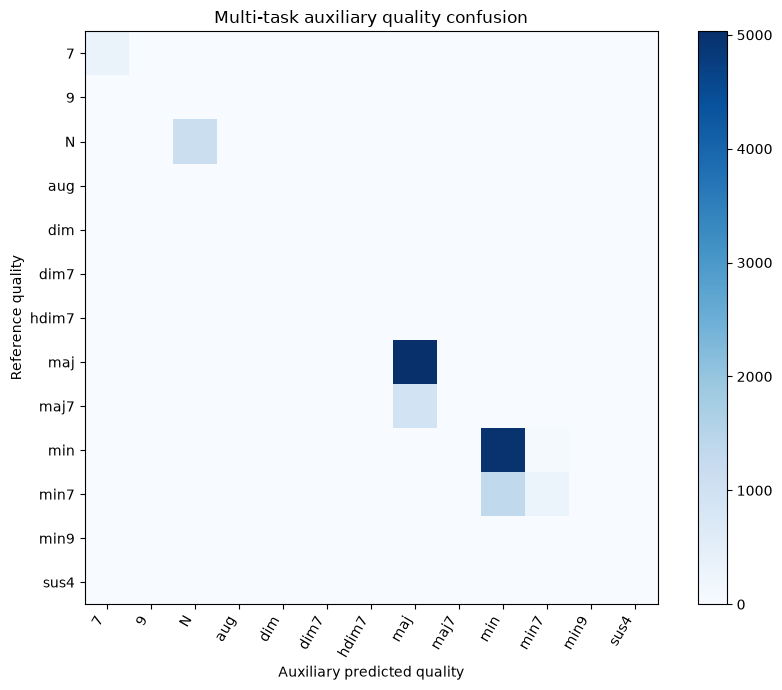

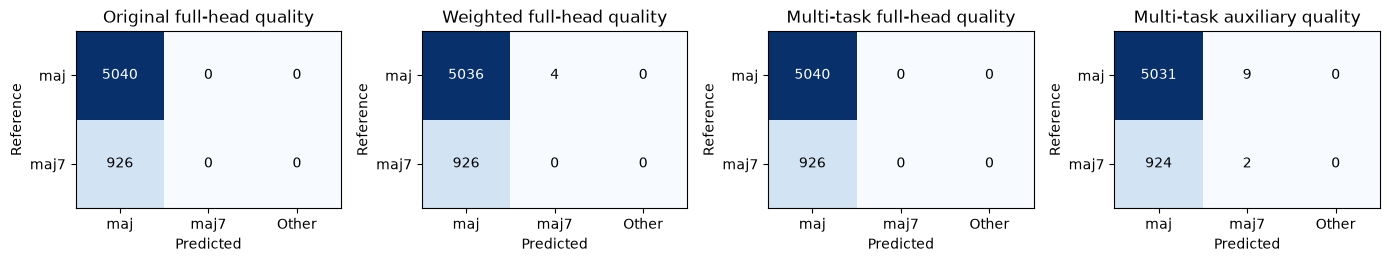

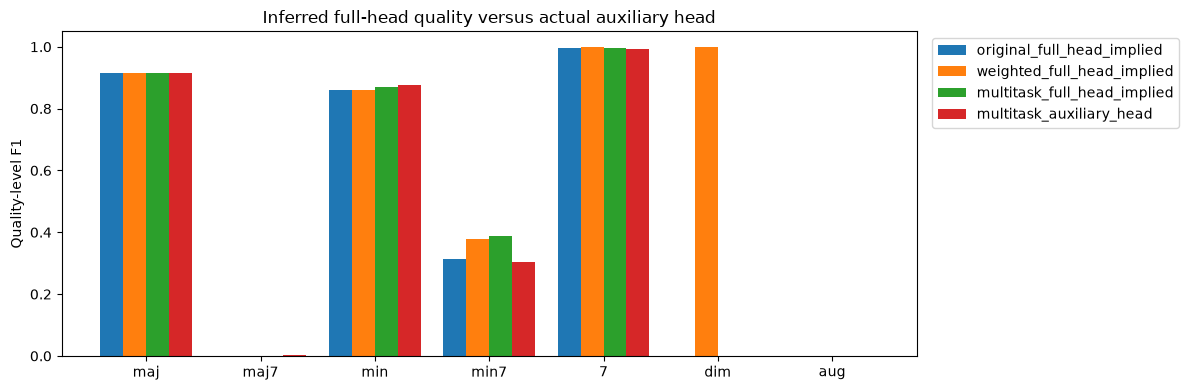

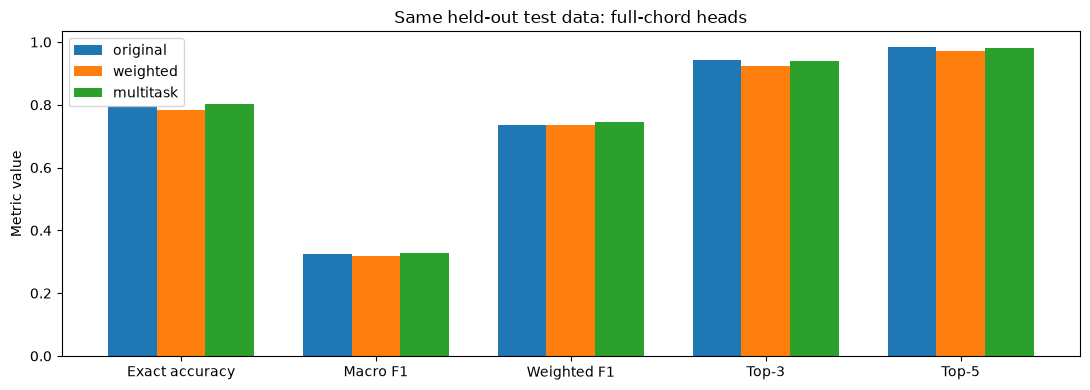

In [15]:
qconf=evaluations['multitask']['quality_confusion']
fig,ax=plt.subplots(figsize=(9,7)); image=ax.imshow(qconf.numpy(),cmap='Blues')
ax.set_xticks(range(Q),quality_mapping.labels,rotation=60,ha='right'); ax.set_yticks(range(Q),quality_mapping.labels)
ax.set(xlabel='Auxiliary predicted quality',ylabel='Reference quality',title='Multi-task auxiliary quality confusion')
fig.colorbar(image,ax=ax); fig.tight_layout(); fig.savefig(RUN_DIR/'quality_confusion.png',dpi=170); plt.show()
implied={}
for name,data in evaluations.items():
    matrix=torch.zeros(Q,Q+1,dtype=torch.int64)
    for i,j in data['confusion'].nonzero().tolist():
        qi=quality_mapping.chord_to_quality[i]; qj=quality_mapping.chord_to_quality[j]
        if qi>=0: matrix[qi,qj if qj>=0 else Q]+=data['confusion'][i,j]
    implied[name]=matrix
major_id=quality_mapping.labels.index('maj'); seventh_id=quality_mapping.labels.index('maj7')
fig,axes=plt.subplots(1,4,figsize=(14,4))
items=[('Original full-head quality',implied['original']),('Weighted full-head quality',implied['weighted']),
       ('Multi-task full-head quality',implied['multitask']),('Multi-task auxiliary quality',qconf)]
for ax,(title,matrix) in zip(axes,items):
    rows=[]
    for qi in (major_id,seventh_id):
        rows.append([int(matrix[qi,major_id]),int(matrix[qi,seventh_id]),int(matrix[qi].sum()-matrix[qi,major_id]-matrix[qi,seventh_id])])
    arr=np.asarray(rows); ax.imshow(arr,cmap='Blues')
    ax.set_xticks(range(3),['maj','maj7','Other']); ax.set_yticks(range(2),['maj','maj7']); ax.set(title=title,xlabel='Predicted',ylabel='Reference')
    for i in range(2):
        for j in range(3): ax.text(j,i,str(arr[i,j]),ha='center',va='center',color='white' if arr[i,j]>arr.max()/2 else 'black')
fig.tight_layout(); fig.savefig(RUN_DIR/'maj_vs_maj7_confusion.png',dpi=170); plt.show()
f1_rows=[]
for name,matrix in implied.items():
    names=tuple(quality_mapping.labels)+('ReservedPrediction',)
    square=torch.zeros(Q+1,Q+1,dtype=torch.int64); square[:Q]=matrix
    _,rows=metrics_from_confusion(square,names,reserved_ids=(Q,))
    for row in rows[:Q]: f1_rows.append({'source':name+'_full_head_implied','quality':row['reference_chord'],'support':row['support'],'f1':row['f1']})
for row in evaluations['multitask']['quality_per_class']:
    f1_rows.append({'source':'multitask_auxiliary_head','quality':row['reference_chord'],'support':row['support'],'f1':row['f1']})
write_csv(RUN_DIR/'per_quality_f1_comparison.csv',f1_rows)
focus=[q for q in ('maj','maj7','min','min7','7','dim','aug') if q in quality_mapping.labels]
fig,ax=plt.subplots(figsize=(12,4)); x=np.arange(len(focus)); width=.2
sources=list(dict.fromkeys(row['source'] for row in f1_rows))
for offset,source in enumerate(sources):
    lookup={r['quality']:r for r in f1_rows if r['source']==source}
    ax.bar(x+(offset-1.5)*width,[lookup[q]['f1'] or 0 for q in focus],width=width,label=source)
ax.set_xticks(x,focus); ax.set(ylabel='Quality-level F1',title='Inferred full-head quality versus actual auxiliary head')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1)); fig.tight_layout(); fig.savefig(RUN_DIR/'per_quality_f1_comparison.png',dpi=170); plt.show()
fig,ax=plt.subplots(figsize=(11,4)); keys=['accuracy','macro_f1','weighted_f1','top3_accuracy','top5_accuracy']; x=np.arange(len(keys))
for offset,name in enumerate(evaluations): ax.bar(x+(offset-1)*.25,[evaluations[name]['metrics'][key] for key in keys],width=.25,label=name)
ax.set_xticks(x,['Exact accuracy','Macro F1','Weighted F1','Top-3','Top-5']); ax.set(ylabel='Metric value',title='Same held-out test data: full-chord heads')
ax.legend(); fig.tight_layout(); fig.savefig(RUN_DIR/'three_model_performance.png',dpi=170); plt.show()
np.savez_compressed(RUN_DIR/'confusions.npz',**{name:data['confusion'].numpy() for name,data in evaluations.items()},
    auxiliary_quality=qconf.numpy(),chord_labels=np.asarray(spec.target_labels),quality_labels=np.asarray(quality_mapping.labels))

## 13. Integrity verification and measured conclusion

There is no test-set tuning or auxiliary re-scoring. The result below is computed from actual evaluation. Auxiliary-quality success alone is not exact refined-chord success. No improvement is assumed in advance.

In [16]:
for path,expected in protected_hashes.items(): assert sha256_file(path)==expected,path
ready=json.loads((DATASET_DIR/'FINAL_DATASET_READY.json').read_text())
for name,expected in ready['artifacts'].items(): assert sha256_file(DATASET_DIR/name)==expected,name
restored=load_multitask_checkpoint(RUN_DIR/'best_multitask.pt',DATASET_DIR,DEVICE)
with torch.no_grad(): first=selected_model(example_inputs); second=restored(example_inputs)
for key in ('chord_logits','quality_logits'): torch.testing.assert_close(first[key],second[key],rtol=0,atol=0)
assert asdict(restored.config)==baseline_config['model']
assert not ENABLE_QUALITY_RESCORING
baseline_maj7=maj7_diagnostic[0]; multi_maj7=maj7_diagnostic[-1]
results={'status':'complete','quality_categories':list(quality_mapping.labels),'quality_count':Q,
    'lambda_quality':LAMBDA_QUALITY,'completed_epochs':len(history),'best_epoch':best_epoch,
    'parameters':sum(p.numel() for p in selected_model.parameters()),
    'full_head_metrics':{name:data['metrics'] for name,data in evaluations.items()},
    'auxiliary_quality_metrics':evaluations['multitask']['quality_metrics'],'auxiliary_maj7':aux_maj7,
    'maj7_split_support':maj7_split_support,'maj7_diagnostic':maj7_diagnostic,
    'maj7_exact_improved_over_original':multi_maj7['exact_top1_accuracy']>baseline_maj7['exact_top1_accuracy'],
    'exact_accuracy_change_percentage_points':100*(evaluations['multitask']['metrics']['accuracy']-evaluations['original']['metrics']['accuracy']),
    'macro_f1_change':evaluations['multitask']['metrics']['macro_f1']-evaluations['original']['metrics']['macro_f1'],
    'old_notebooks_and_checkpoints_unchanged':True,'dataset_artifacts_verified':len(ready['artifacts']),
    'checkpoint_reload_matches':True,'initialized_from_scratch':True,'quality_rescoring_enabled':False,
    'shared_architecture_unchanged':True,'epoch_training_validation_seconds':sum(r['train']['seconds']+r['validation']['seconds'] for r in history),
    'limitations':'One seeded experiment with automatic pseudo-labels and synthetic reference-derived basic inputs; no independent musical correctness claim.'}
atomic_json(RUN_DIR/'results.json',results)
atomic_json(RUN_DIR/'status.json',{'status':'complete','completed_epochs':len(history),'best_epoch':best_epoch})
print('Maj7 exact accuracy:',multi_maj7['exact_top1_accuracy'],'vs original',baseline_maj7['exact_top1_accuracy'])
print('Auxiliary maj7 recall/precision:',aux_maj7['recall'],aux_maj7['precision'])
print('Exact accuracy change (percentage points):',results['exact_accuracy_change_percentage_points'])
print('Macro F1 change:',results['macro_f1_change']); print('Output:',RUN_DIR)
display(results)

Maj7 exact accuracy: 0.0 vs original 0.0
Auxiliary maj7 recall/precision: 0.0021598272138228943 0.125
Exact accuracy change (percentage points): 0.8737657171272395
Macro F1 change: 0.0029366149759922355
Output: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\multitask_transformer\multitask_20261020_164527_051309


{'status': 'complete',
 'quality_categories': ['7',
  '9',
  'N',
  'aug',
  'dim',
  'dim7',
  'hdim7',
  'maj',
  'maj7',
  'min',
  'min7',
  'min9',
  'sus4'],
 'quality_count': 13,
 'lambda_quality': 0.5,
 'completed_epochs': 4,
 'best_epoch': 1,
 'parameters': 350751,
 'full_head_metrics': {'original': {'valid_targets': 14077,
   'exact_correct': 11192,
   'accuracy': 0.7950557647225971,
   'macro_f1': 0.32597766423563834,
   'weighted_f1': 0.7349953243341616,
   'macro_classes': 104,
   'macro_policy': 'Positive test-reference support, excluding reserved PAD/UNK; supervised N included.',
   'unweighted_ce': 0.8552253938850933,
   'top3_accuracy': 0.9417489521915181,
   'top5_accuracy': 0.9848689351424309,
   'musical_targets': 12965,
   'correct_root_wrong_quality': 2484,
   'correct_root_wrong_quality_fraction': 0.19159274971075974},
  'weighted': {'valid_targets': 14077,
   'exact_correct': 11050,
   'accuracy': 0.7849683881508844,
   'macro_f1': 0.3198755370699484,
   'weight

## Saved files and interpretation

Load `best_multitask.pt` with `load_multitask_checkpoint(path, DATASET_DIR)`. The outputs are `chord_logits` and `quality_logits`; they are evaluated separately. No auxiliary inference fusion was applied.

The run saves training history, chord-to-quality mapping, per-chord and individual-quality scores, auxiliary quality metrics, maj7 diagnostics/examples, three-model comparison, confusion arrays and plots. Zero-support labels remain visible; macro F1 includes only positive-reference-support classes. Legitimate N remains supervised.

If exact maj7 accuracy does not improve, this experiment has not met the primary extension-refinement objective, even if the auxiliary head improves. Single-seed results need further validation-based confirmation; repeated test-directed tuning would compromise the held-out comparison. Automatic pseudo-labels are not independent musical ground truth.